이번에는 따로 md 없이 작업하였습니다.

시작 시간: `2026-10-13 11:43:50`

# 1. 세 사진 나란히 출력

Palm (5-finger.jpg): 가로 3060px, 세로 4080px
Fist (0-finger.jpg): 가로 3060px, 세로 4080px
Two fingers (2-finger.jpg): 가로 3060px, 세로 4080px


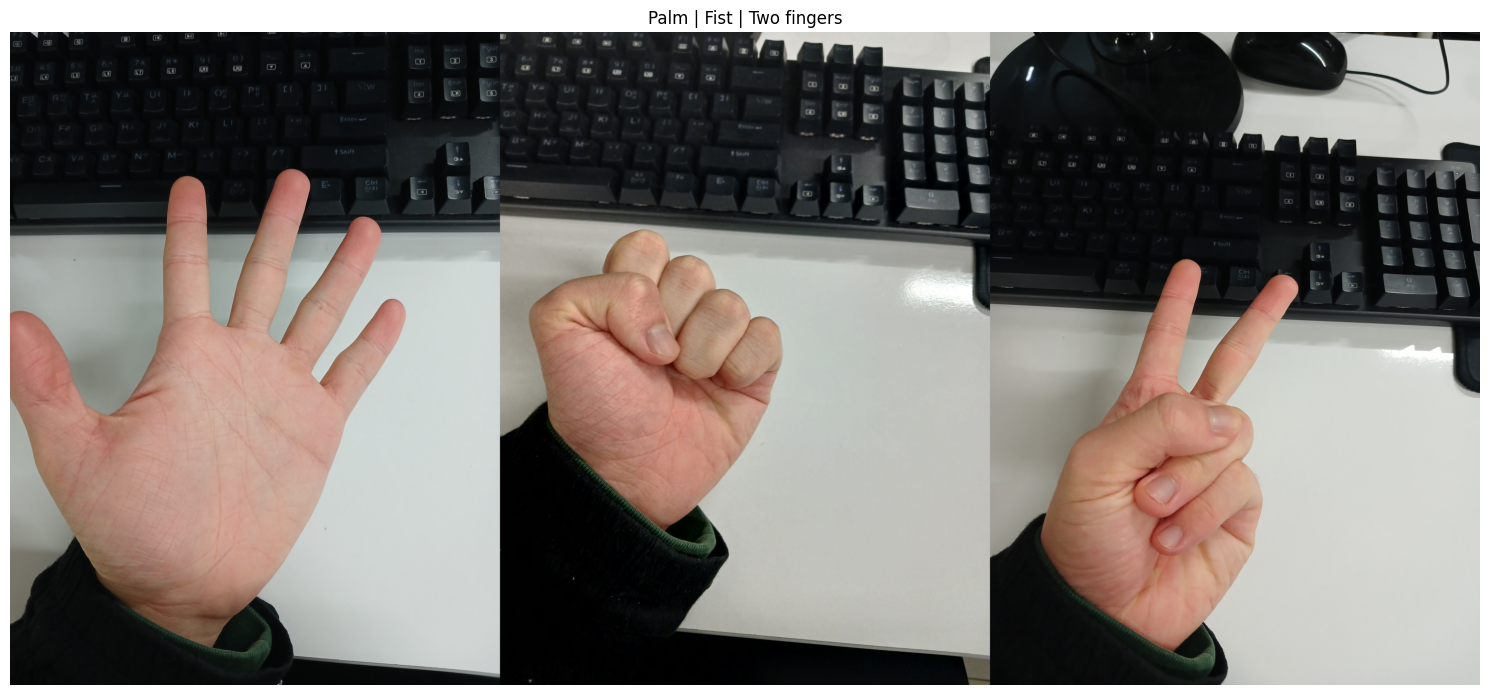

In [20]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

data_dir = Path('datas') if Path('datas/5-finger.jpg').exists() else Path('hand_filter/datas')
image_files = {
    'Palm': '5-finger.jpg',
    'Fist': '0-finger.jpg',
    'Two fingers': '2-finger.jpg',
}
images = {}

# 이미지 3개 가져오기 (파일 이름으로 순회)
for name, filename in image_files.items():
    # 한글이 포함된 Windows 경로에서도 읽을 수 있도록 디코딩합니다.
    # 메모리에있는 압축된 이미지 데이터를 픽셀 배열로 변환하는 함수
    image = cv2.imdecode(
      # 바이너리 파일이면 모두 읽는 numpy 함수 (신기하다!) -> 바이너리로 변환
      np.fromfile(data_dir / filename, dtype=np.uint8), 
      # 기본 BGR로 읽어오는 함수
      cv2.IMREAD_COLOR
    )
    if image is None:
        raise ValueError(f'이미지를 읽을 수 없습니다: {filename}')
    # 이름: numpyarray 딕셔너리 변환
    images[name] = image
    # 크기 검수
    height, width = image.shape[:2]
    print(f'{name} ({filename}): 가로 {width}px, 세로 {height}px')

# 이미지 높이중에서 가장 낮은거에 맞춰주기
display_height = min(image.shape[0] for image in images.values())
display_images = []
# 출력할 ㅣㅇ미지 만들어주기
for image in images.values():
    height, width = image.shape[:2]
    if height != display_height:
        # 이미지 리사이징 해주기 비율 변경
        image = cv2.resize(image, (round(width * display_height / height), display_height))
    display_images.append(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

# 여러 배열을 지정한 축 방향으로 이어주기 (그냥 간단히 말해서 height고정, weight1+weight2+weight3)
joined_image = np.concatenate(display_images, axis=1)
plt.figure(figsize=(15, 7))
plt.imshow(joined_image)
plt.title('Palm | Fist | Two fingers')
plt.axis('off')
plt.tight_layout()
plt.show()


# 2. 피부색 범위로 마스킹
실패와 성공 모두 하기

넓은 범위: 하한 [0, 0, 40], 상한 [100, 255, 255]
좁힌 범위: 하한 [0, 50, 50], 상한 [25, 220, 255]
좁힌 마스크의 흰색 픽셀 수: 3,611,423


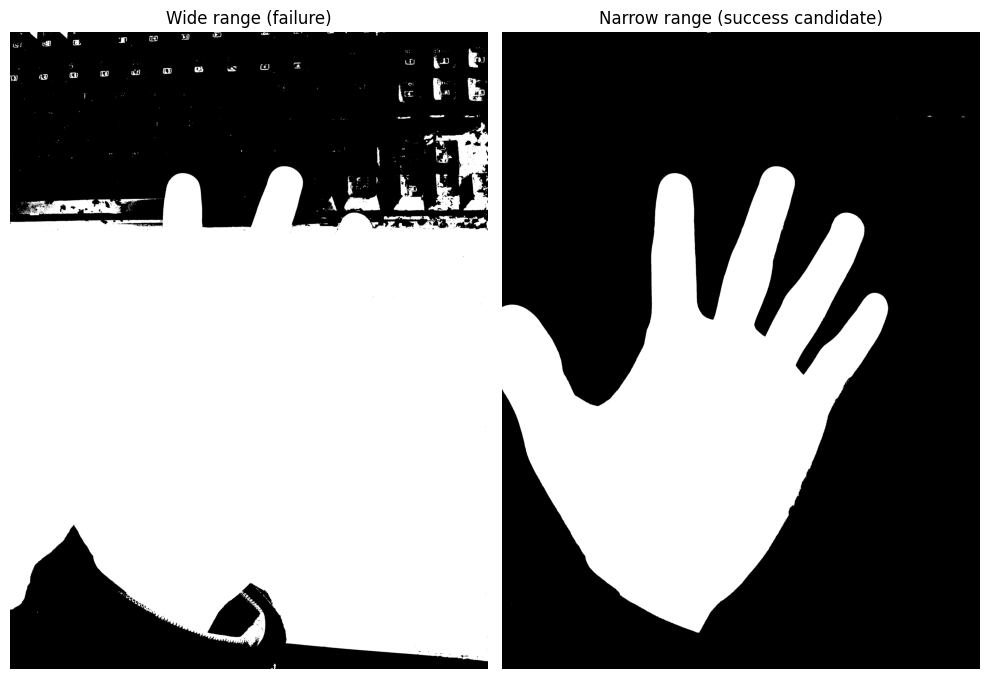

In [21]:
# 하나의 이미지만 사용해서 진행하기
palm_image = images['Palm']
palm_hsv = cv2.cvtColor(palm_image, cv2.COLOR_BGR2HSV)

# OpenCV HSV 범위: H=0~179, S=0~255, V=0~255
# [실패 필터] - 일부러 범위를 좀 넓게 잡아서 흰색(전체 명도/투명도) ~ 하늘색 정도까지 모두 포함하게 하기
lower_wide = np.array([0, 0, 40], dtype=np.uint8)
upper_wide = np.array([100, 255, 255], dtype=np.uint8)

# [성공 필터] - 필터를 살구색(빨강~노랑) 정도만 잡고 약간 채도와 밝기 최저치를 높여서 잡아주기.
lower_skin = np.array([0, 50, 50], dtype=np.uint8)
upper_skin = np.array([25, 220, 255], dtype=np.uint8)

wide_mask = cv2.inRange(palm_hsv, lower_wide, upper_wide)
skin_mask = cv2.inRange(palm_hsv, lower_skin, upper_skin)
white_pixel_count = np.count_nonzero(skin_mask == 255)

print(f'넓은 범위: 하한 {lower_wide.tolist()}, 상한 {upper_wide.tolist()}')
print(f'좁힌 범위: 하한 {lower_skin.tolist()}, 상한 {upper_skin.tolist()}')
print(f'좁힌 마스크의 흰색 픽셀 수: {white_pixel_count:,}')

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
for ax, mask, title in zip(
    axes,
    [wide_mask, skin_mask],
    ['Wide range (failure)', 'Narrow range (success candidate)'],
):
    ax.imshow(mask, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

fig.tight_layout()
plt.show()


In [22]:
print(f"{np.count_nonzero(palm_image):,}")

37,453,075


# 3. 손만 컬러

2번 마스크의 흰색 픽셀 수: 3,611,423
컬러로 복원한 픽셀 수: 3,611,423
픽셀 수 일치 여부: True


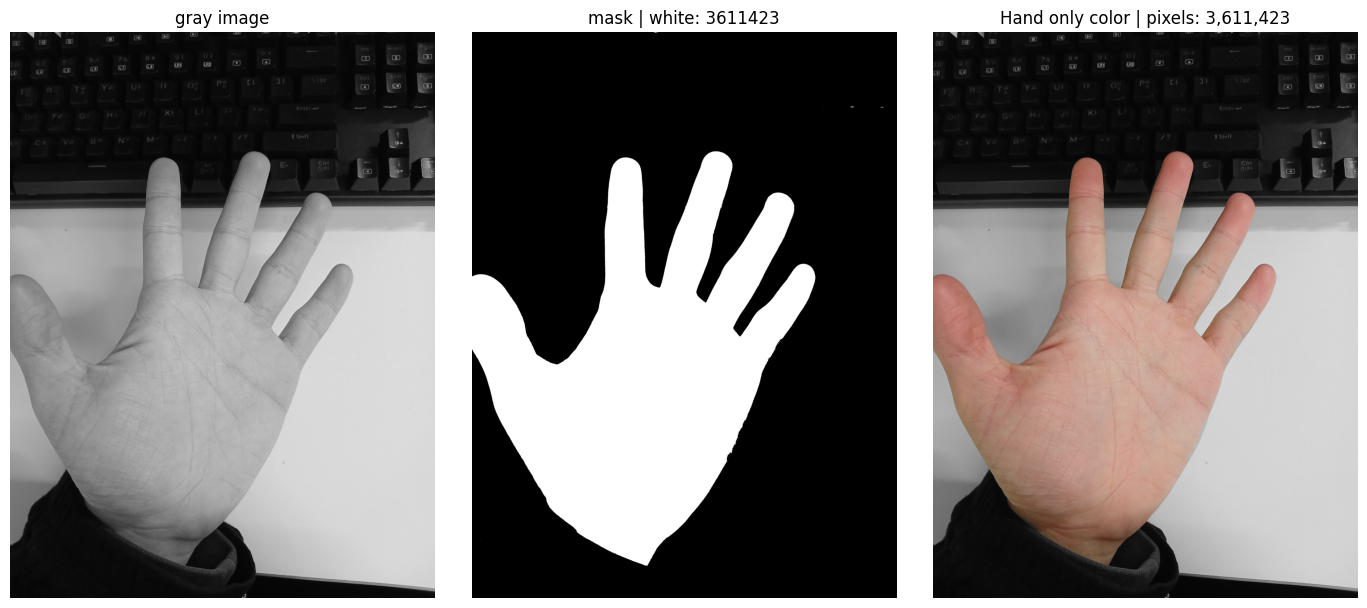

In [23]:
# 회색 이미지를 3채널로 바꿔 원본과 같은 형태로 만듭니다.
palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)
palm_color = cv2.cvtColor(palm_gray, cv2.COLOR_GRAY2BGR)

# 성공 마스크가 흰색인 위치에만 원본 색을 복원합니다.
color_positions = skin_mask == 255
palm_color[color_positions] = palm_image[color_positions]

# 채널 수가 아니라 원본 색을 복원한 픽셀 위치의 수를 셉니다.
color_pixel_count = np.count_nonzero(color_positions)
print(f'2번 마스크의 흰색 픽셀 수: {white_pixel_count:,}')
print(f'컬러로 복원한 픽셀 수: {color_pixel_count:,}')
print(f'픽셀 수 일치 여부: {color_pixel_count == white_pixel_count}')

fig, axes = plt.subplots(1, 3, figsize=(14, 6))


axes[0].imshow(palm_gray, cmap="gray")
axes[0].set_title(f'gray image')
axes[0].axis("off")

axes[1].imshow(skin_mask, cmap="gray")
axes[1].set_title(f'mask | white: {white_pixel_count}')
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(palm_color, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Hand only color | pixels: {color_pixel_count:,}')
axes[2].axis("off")

plt.tight_layout()
plt.show()


# 확인 완료
기존의 이미지가 손 말고 모두 흑백에 가까워서 햇갈릴 수 있는데 손목의 옷부분이 아주 조금 원래 초록이였는데 회색이 된 것을 확인할 수 있습니다.

# 4. Canny 적용
Canny를 그냥 적용하면 키보드의 숫자부분이 너무 강해서 무조건 남기 때문에 Opening를 통해서 흰색 잡음을 제거하고 진행해주겠습니다.

문제에서 이상하다 생각이 드는 부분은 **낮은 임계값에서 선이 더 많이 나온다고 하는데 Canny는 임계치보다 높으면 더 확실하게 잡는 형태입니다.**  

낮은 임계값 (50, 100): 흰색 픽셀 23,473개
높은 임계값 (60, 120): 흰색 픽셀 22,119개


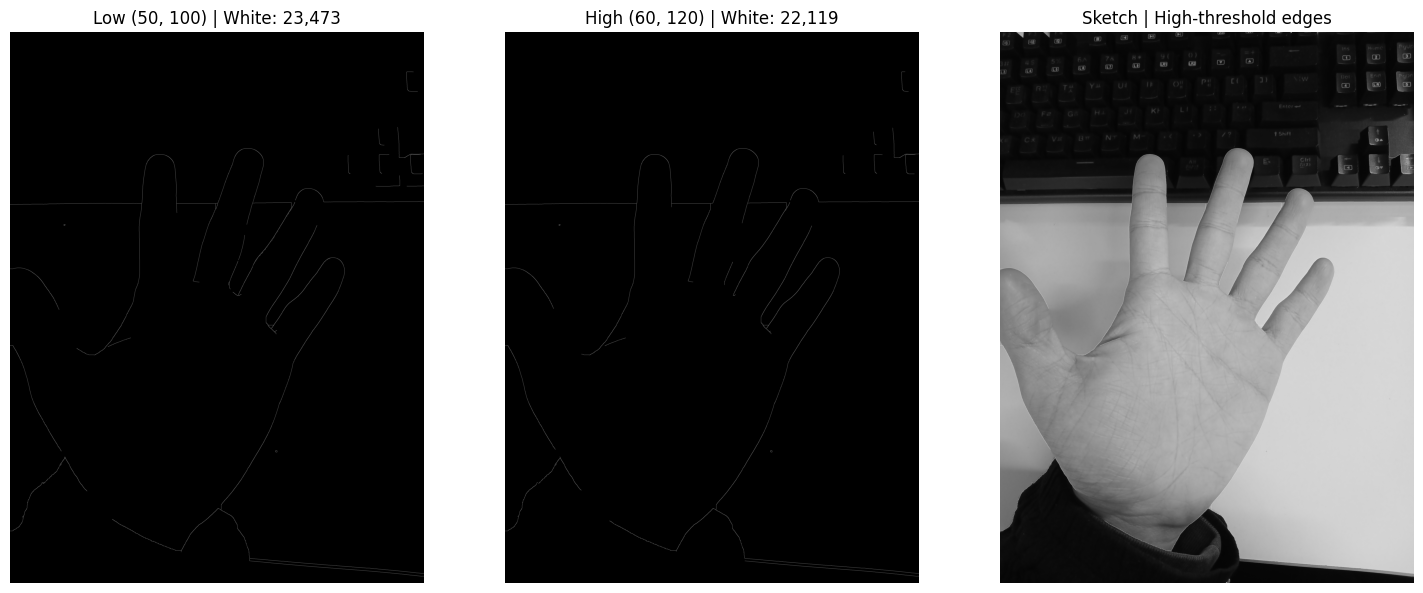

In [40]:
# 회색 이미지는 스케치 배경으로만 사용합니다.
palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)

# 컬러 원본에 3x3 커널로 침식 3회 후 팽창 3회를 적용합니다.
opening_kernel = np.ones((3, 3), dtype=np.uint8)
palm_eroded = cv2.erode(palm_image, opening_kernel, iterations=20)
palm_opened = cv2.dilate(palm_eroded, opening_kernel, iterations=20)

# 윤곽선 검출에는 전처리된 BGR 3채널 컬러 이미지를 넣습니다.
canny_input = cv2.GaussianBlur(palm_opened, (5, 5), 0)

low_thresholds = (50, 100)
high_thresholds = (60, 120)
# 같은 입력에서는 낮은 임계값이 보통 더 많은 선을 남깁니다.
edges_low = cv2.Canny(canny_input, *low_thresholds)
edges_high = cv2.Canny(canny_input, *high_thresholds)

low_white_pixel_count = np.count_nonzero(edges_low == 255)
high_white_pixel_count = np.count_nonzero(edges_high == 255)
print(f'낮은 임계값 {low_thresholds}: 흰색 픽셀 {low_white_pixel_count:,}개')
print(f'높은 임계값 {high_thresholds}: 흰색 픽셀 {high_white_pixel_count:,}개')

# 높은 임계값에서 검출된 선만 회색 사진 위에 흰색으로 덧그립니다.
palm_sketch = palm_gray.copy()
palm_sketch[edges_high == 255] = 255

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes[0].imshow(edges_low, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f'Low {low_thresholds} | White: {low_white_pixel_count:,}')
axes[1].imshow(edges_high, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'High {high_thresholds} | White: {high_white_pixel_count:,}')
axes[2].imshow(palm_sketch, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Sketch | High-threshold edges')
for ax in axes:
    ax.axis('off')

fig.tight_layout()
plt.show()


# 방향성 수정
이대로면 무조건 키보드와 흰색 배경이 손보다 높게 나오기 때문에 그냥 마스킹을 통해 진행을 해야겠다고 생각했습니다.

방향성은 그냥 이미지 전체를 그냥 가우시안 블러를 강하게 먹인 뒤 그 위에 손이미지를 다시 올려서 진행하였습니다.

그리고 낮은 임계치에서 더 적은 선이 나오는게 이상해서 그냥 임의로 높은 임계치를 주어 나오는 선이 적게 만들었습니다.

블러 커널: (51, 51), 반복: 100회, sigma: 0
낮은 임계값 (임의로 낮은 임계값을 높여서 설정) (150, 200): 흰색 픽셀 8,388개
높은 임계값 (60, 120): 흰색 픽셀 16,835개


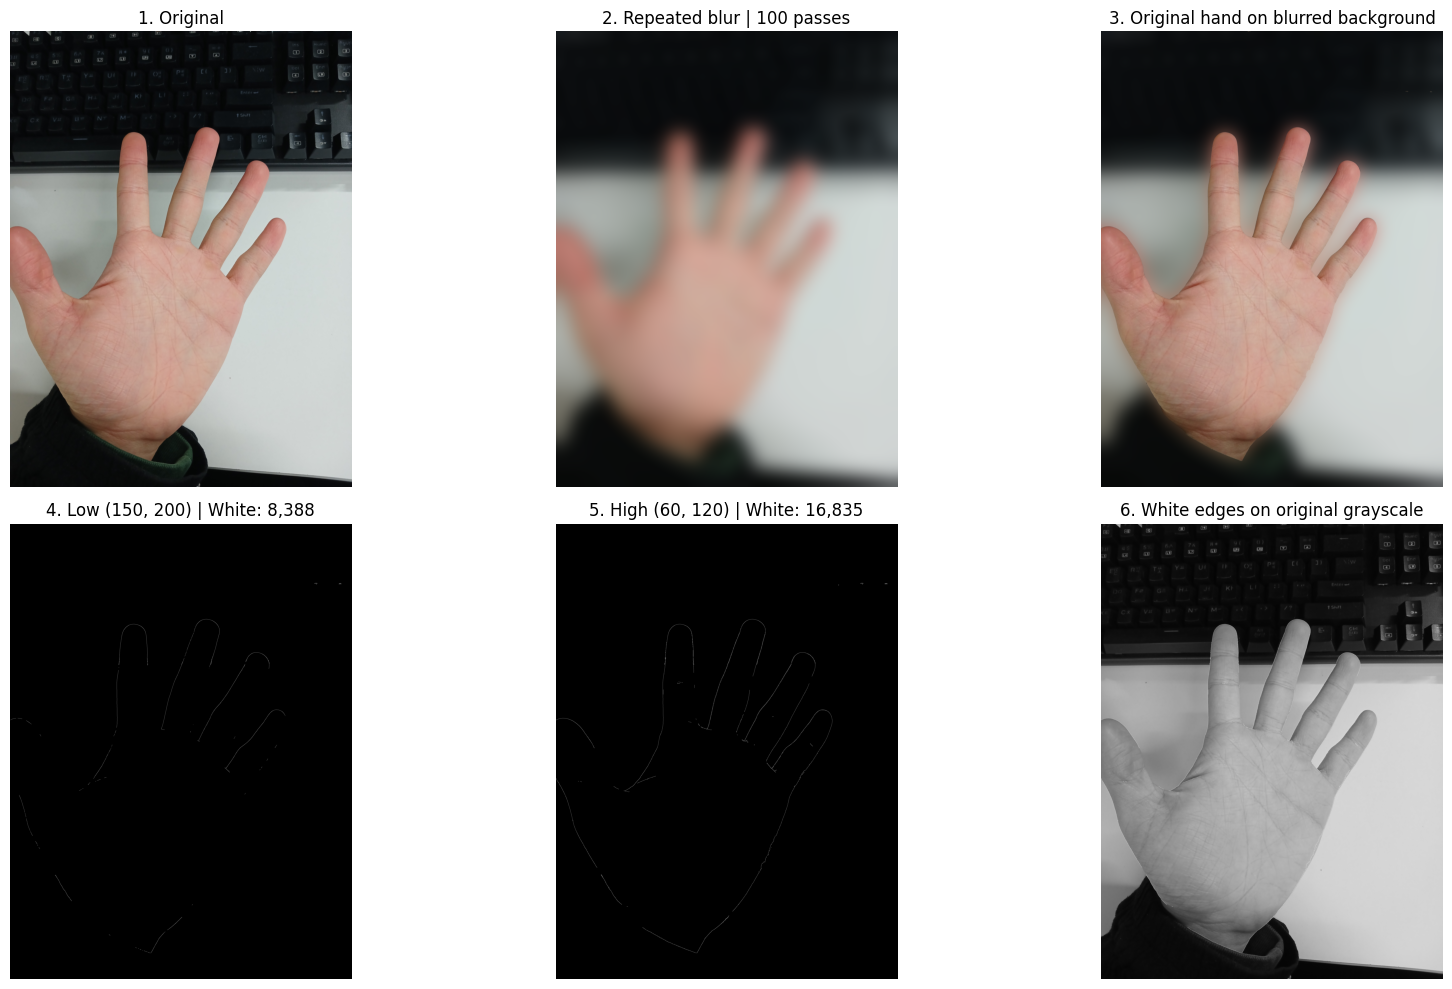

In [48]:
# 작은 커널로 반복해서 흐린 뒤, 성공 마스크 위치에 원본 손을 복원합니다.
blur_kernel = (51, 51)
blur_sigma = 0
blur_iterations = 100
background_blur = palm_image.copy()
for _ in range(blur_iterations):
    background_blur = cv2.GaussianBlur(background_blur, blur_kernel, blur_sigma)

hand_restored = background_blur.copy()
hand_positions = skin_mask == 255
hand_restored[hand_positions] = palm_image[hand_positions]

# 합성한 컬러 이미지에 기존의 낮은/높은 임계값을 적용합니다.
low_thresholds = (150, 200)
high_thresholds = (60, 120)

blur_edges_low = cv2.Canny(hand_restored, *low_thresholds)
blur_edges_high = cv2.Canny(hand_restored, *high_thresholds)
blur_low_count = np.count_nonzero(blur_edges_low == 255)
blur_high_count = np.count_nonzero(blur_edges_high == 255)
print(f'블러 커널: {blur_kernel}, 반복: {blur_iterations}회, sigma: {blur_sigma}')
print(f'낮은 임계값 (임의로 낮은 임계값을 높여서 설정) {low_thresholds}: 흰색 픽셀 {blur_low_count:,}개')
print(f'높은 임계값 {high_thresholds}: 흰색 픽셀 {blur_high_count:,}개')

# 원본의 회색 사진 위에 높은 임계값의 윤곽선을 흰색으로 덧그립니다.
blur_sketch = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)
blur_sketch[blur_edges_high == 255] = 255

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
stages = [
    (palm_image, '1. Original'),
    (background_blur, f'2. Repeated blur | {blur_iterations} passes'),
    (hand_restored, '3. Original hand on blurred background'),
    (blur_edges_low, f'4. Low {low_thresholds} | White: {blur_low_count:,}'),
    (blur_edges_high, f'5. High {high_thresholds} | White: {blur_high_count:,}'),
    (blur_sketch, '6. White edges on original grayscale'),
]
for ax, (stage_image, title) in zip(axes.flat, stages):
    if stage_image.ndim == 3:
        ax.imshow(cv2.cvtColor(stage_image, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(stage_image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

fig.tight_layout()
plt.show()


# 5. 주먹: 같은 피부색 범위와 공통 크롭 비교

HSV 하한: [0, 50, 50], 상한: [25, 220, 255]
손바닥 컬러 픽셀: 3,611,731 | 주먹 컬러 픽셀: 1,888,400
두 픽셀 수의 차이: 1,723,331
공통 크롭 범위: x=0:2469, y=861:3838
크롭 크기: 가로 2469px, 세로 2977px


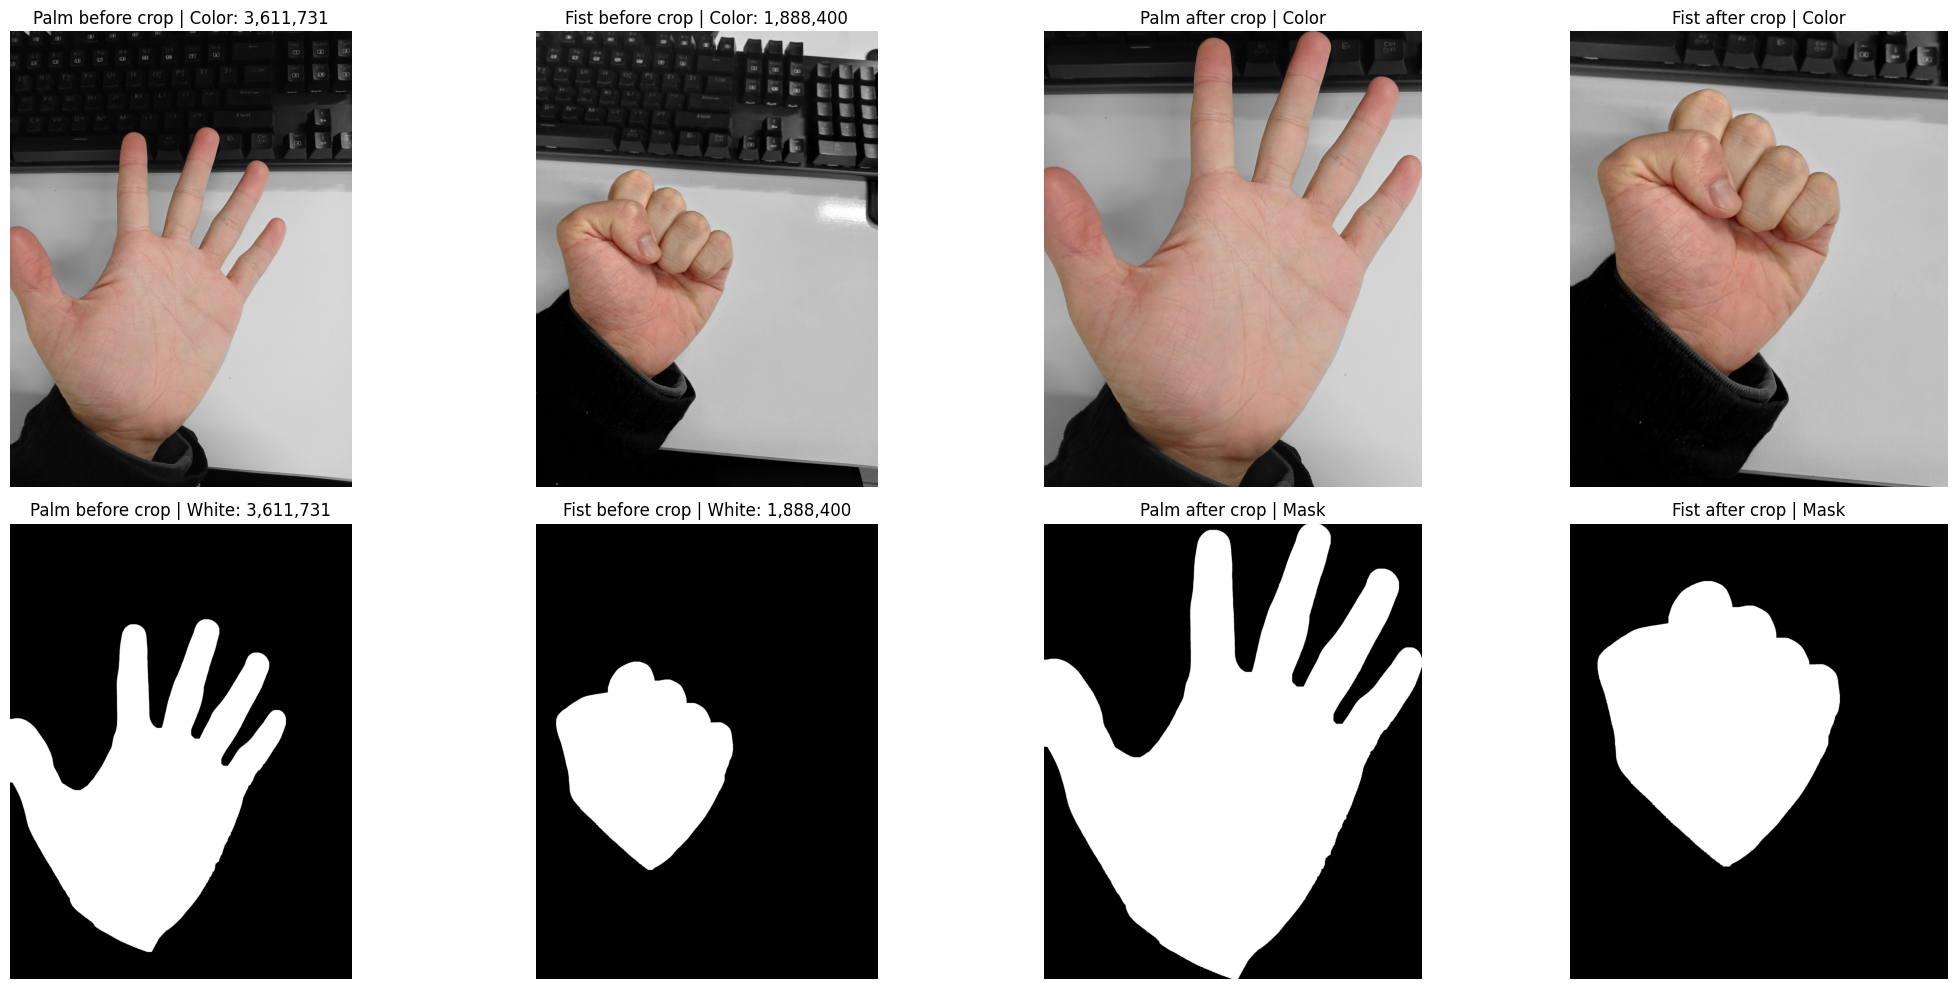

In [54]:
# 3번과 같은 HSV 하한/상한을 주먹 사진에 적용합니다.
fist_image = images['Fist']
fist_hsv = cv2.cvtColor(fist_image, cv2.COLOR_BGR2HSV)
fist_mask = cv2.inRange(fist_hsv, lower_skin, upper_skin)

mask_kernel = np.ones((5, 5), dtype=np.uint8)
mask_iterations = 10
clean_masks = []
for mask in [skin_mask, fist_mask]:
    # Opening: 작은 흰색 잡음을 제거합니다.
    cleaned = cv2.erode(mask, mask_kernel, iterations=mask_iterations)
    cleaned = cv2.dilate(cleaned, mask_kernel, iterations=mask_iterations)
    # Closing: 손 내부의 작은 검정 틈을 메웁니다.
    cleaned = cv2.dilate(cleaned, mask_kernel, iterations=mask_iterations)
    cleaned = cv2.erode(cleaned, mask_kernel, iterations=mask_iterations)
    clean_masks.append(cleaned)
palm_mask_clean, fist_mask_clean = clean_masks

# 컬러 복원, 픽셀 수, 크롭 모두 정리된 마스크를 사용합니다.
palm_positions_clean = palm_mask_clean == 255
palm_comparison_color = cv2.cvtColor(
    cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY), cv2.COLOR_GRAY2BGR
)
palm_comparison_color[palm_positions_clean] = palm_image[palm_positions_clean]
fist_positions = fist_mask_clean == 255
fist_gray = cv2.cvtColor(fist_image, cv2.COLOR_BGR2GRAY)
fist_color = cv2.cvtColor(fist_gray, cv2.COLOR_GRAY2BGR)
fist_color[fist_positions] = fist_image[fist_positions]

palm_color_count = np.count_nonzero(palm_positions_clean)
fist_color_count = np.count_nonzero(fist_positions)
print(f'HSV 하한: {lower_skin.tolist()}, 상한: {upper_skin.tolist()}')
print(f'손바닥 컬러 픽셀: {palm_color_count:,} | 주먹 컬러 픽셀: {fist_color_count:,}')
print(f'두 픽셀 수의 차이: {palm_color_count - fist_color_count:,}')

# 두 마스크의 OR 영역을 모두 포함하는 공통 사각형으로 크롭합니다.
if palm_mask_clean.shape != fist_mask_clean.shape:
    raise ValueError('공통 좌표로 크롭하려면 두 사진의 가로·세로가 같아야 합니다.')
comparison_mask = palm_positions_clean | fist_positions
ys, xs = np.where(comparison_mask)
if len(xs) == 0:
    raise ValueError('피부색 마스크에 선택된 픽셀이 없습니다.')
x1, x2 = xs.min(), xs.max() + 1
y1, y2 = ys.min(), ys.max() + 1
palm_crop = palm_comparison_color[y1:y2, x1:x2]
fist_crop = fist_color[y1:y2, x1:x2]
palm_mask_crop = palm_mask_clean[y1:y2, x1:x2]
fist_mask_crop = fist_mask_clean[y1:y2, x1:x2]
print(f'공통 크롭 범위: x={x1}:{x2}, y={y1}:{y2}')
print(f'크롭 크기: 가로 {x2 - x1}px, 세로 {y2 - y1}px')

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
comparison_images = [
    (palm_comparison_color, f'Palm before crop | Color: {palm_color_count:,}'),
    (fist_color, f'Fist before crop | Color: {fist_color_count:,}'),
    (palm_crop, 'Palm after crop | Color'),
    (fist_crop, 'Fist after crop | Color'),
    (palm_mask_clean, f'Palm before crop | White: {palm_color_count:,}'),
    (fist_mask_clean, f'Fist before crop | White: {fist_color_count:,}'),
    (palm_mask_crop, 'Palm after crop | Mask'),
    (fist_mask_crop, 'Fist after crop | Mask'),
]
for ax, (image, title) in zip(axes.flat, comparison_images):
    if image.ndim == 3:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

fig.tight_layout()
plt.show()


# 두 위치의 차이
마스크 + 같은 크기의 크롭을 하고 비교하였을 때 주먹이 아예 손바닥 안에 들어가는 것을 확인할 수 있습니다.

차이 픽셀 수는 1,723,331개 입니다.

# 6. 손가락 두 개: 같은 피부색 범위로 손만 컬러

HSV 하한: [0, 50, 50], 상한: [25, 220, 255]
2-finger 마스크의 흰색 / 컬러 복원 픽셀 수: 2,011,064


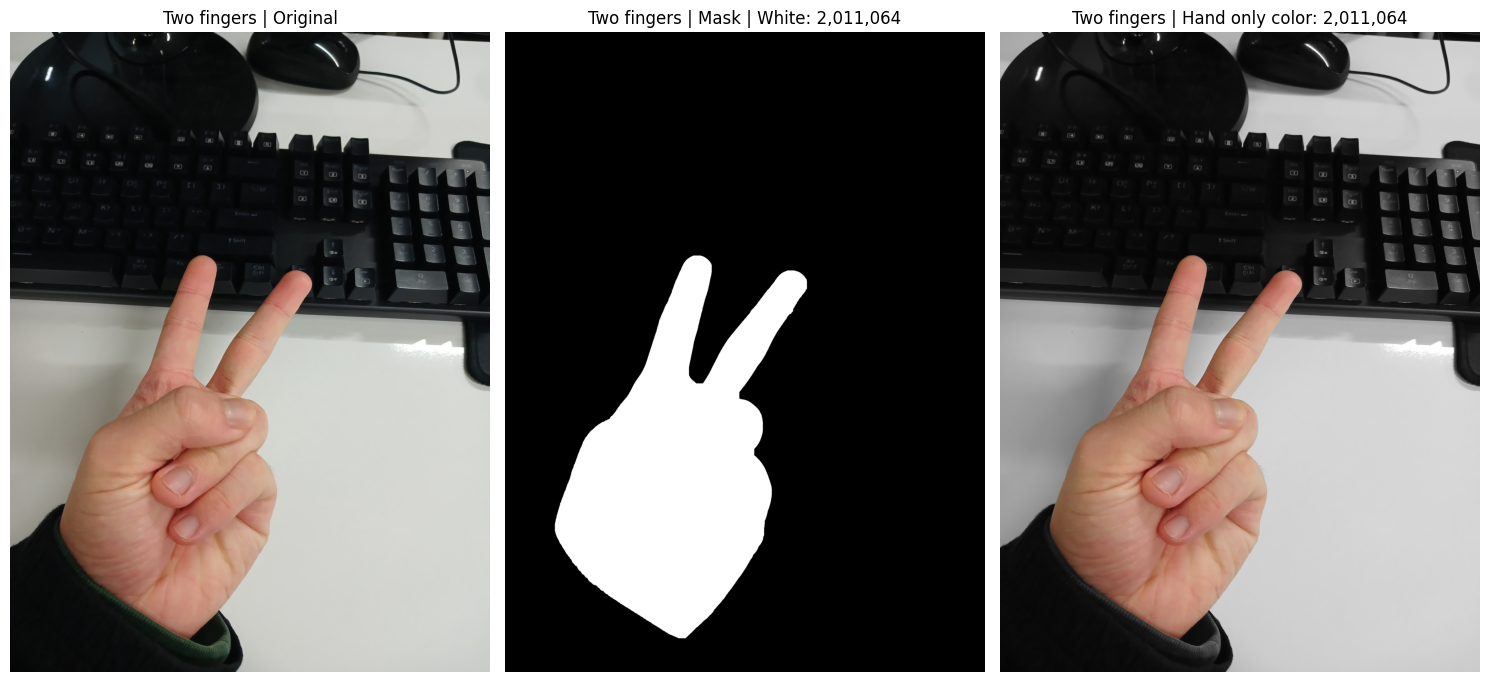

In [55]:
two_finger_image = images['Two fingers']
two_finger_hsv = cv2.cvtColor(two_finger_image, cv2.COLOR_BGR2HSV)
two_finger_mask = cv2.inRange(two_finger_hsv, lower_skin, upper_skin)

# 주먹과 같은 커널 및 반복 횟수로 Opening과 Closing을 적용합니다.
two_finger_mask_clean = cv2.erode(two_finger_mask, mask_kernel, iterations=mask_iterations)
two_finger_mask_clean = cv2.dilate(two_finger_mask_clean, mask_kernel, iterations=mask_iterations)
two_finger_mask_clean = cv2.dilate(two_finger_mask_clean, mask_kernel, iterations=mask_iterations)
two_finger_mask_clean = cv2.erode(two_finger_mask_clean, mask_kernel, iterations=mask_iterations)

# 회색 배경에서 정리된 마스크 위치만 원래 색으로 복원합니다.
two_finger_gray = cv2.cvtColor(two_finger_image, cv2.COLOR_BGR2GRAY)
two_finger_color = cv2.cvtColor(two_finger_gray, cv2.COLOR_GRAY2BGR)
two_finger_positions = two_finger_mask_clean == 255
two_finger_color[two_finger_positions] = two_finger_image[two_finger_positions]
two_finger_color_count = np.count_nonzero(two_finger_positions)
print(f'HSV 하한: {lower_skin.tolist()}, 상한: {upper_skin.tolist()}')
print(f'2-finger 마스크의 흰색 / 컬러 복원 픽셀 수: {two_finger_color_count:,}')

fig, axes = plt.subplots(1, 3, figsize=(15, 7))
axes[0].imshow(cv2.cvtColor(two_finger_image, cv2.COLOR_BGR2RGB))
axes[0].set_title('Two fingers | Original')
axes[1].imshow(two_finger_mask_clean, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'Two fingers | Mask | White: {two_finger_color_count:,}')
axes[2].imshow(cv2.cvtColor(two_finger_color, cv2.COLOR_BGR2RGB))
axes[2].set_title(f'Two fingers | Hand only color: {two_finger_color_count:,}')
for ax in axes:
    ax.axis('off')

fig.tight_layout()
plt.show()


손가락 끝이 회색으로 빠진 부분을 찾아보았는데 없었습니다.
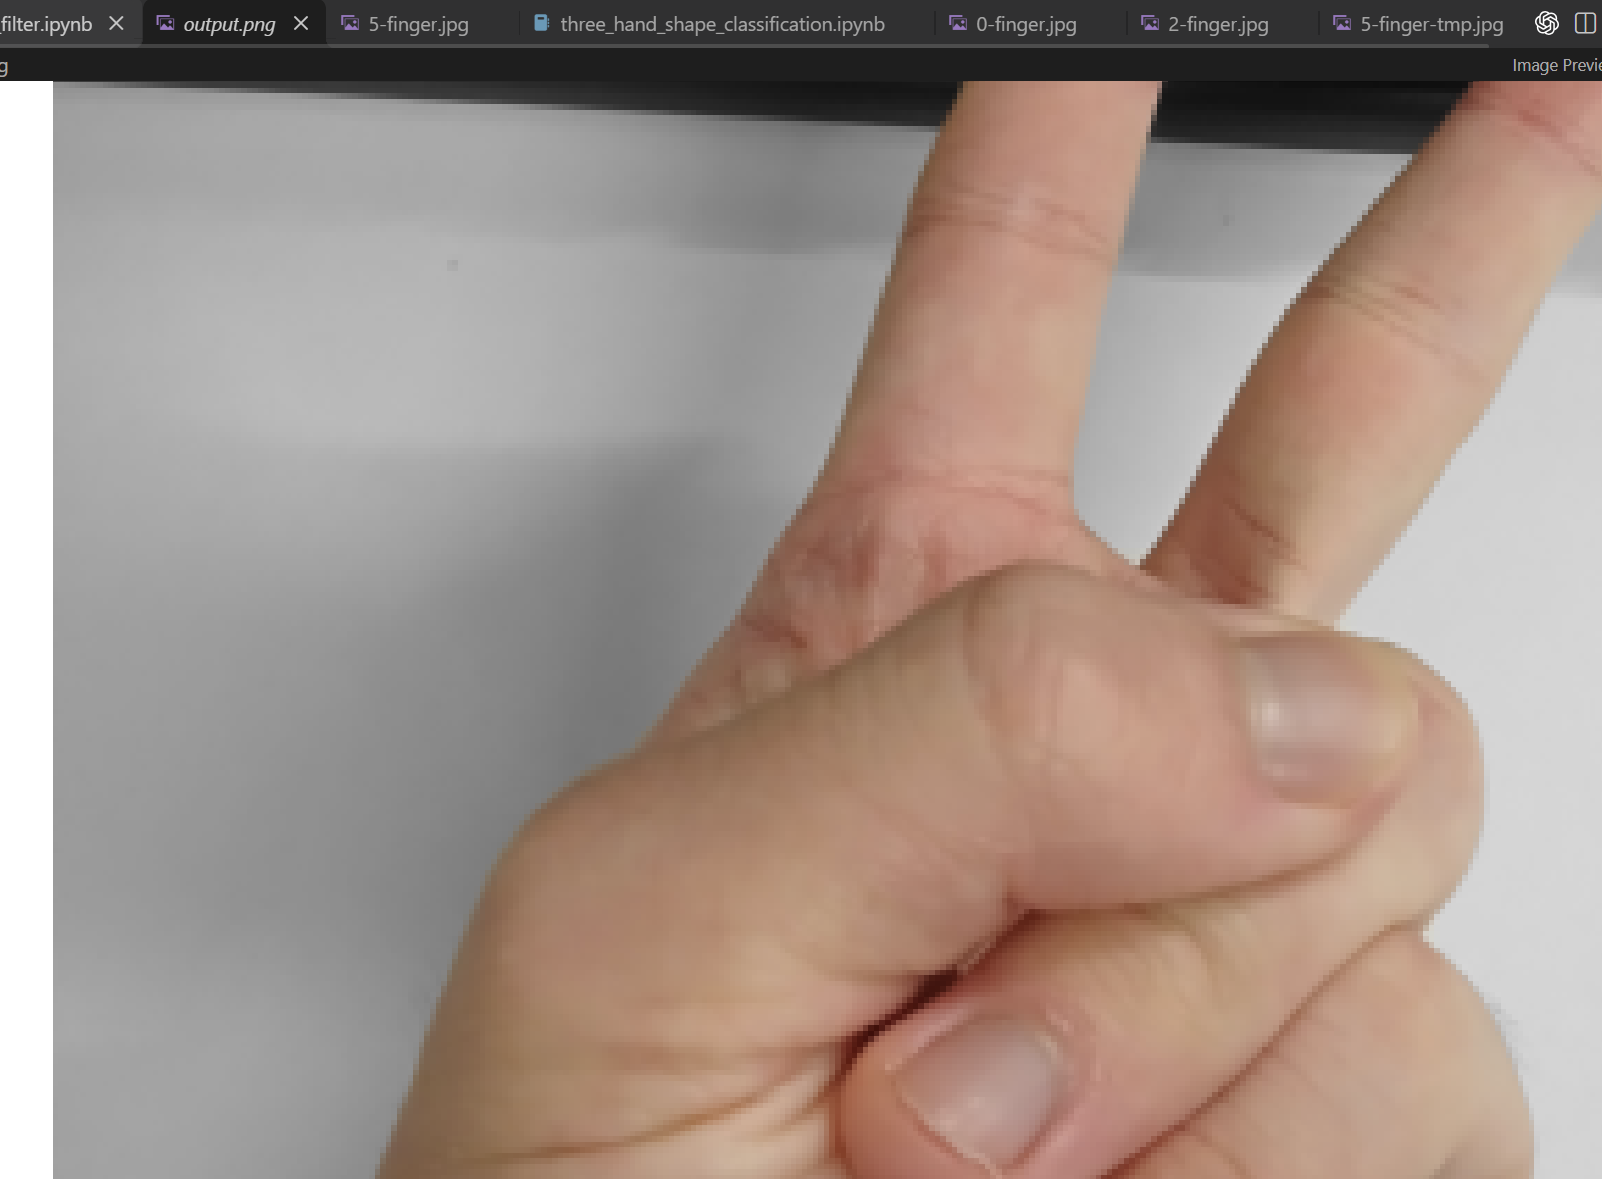

# 7. 한 장 포스터

손바닥 마스크의 흰색 픽셀 수: 3,611,731


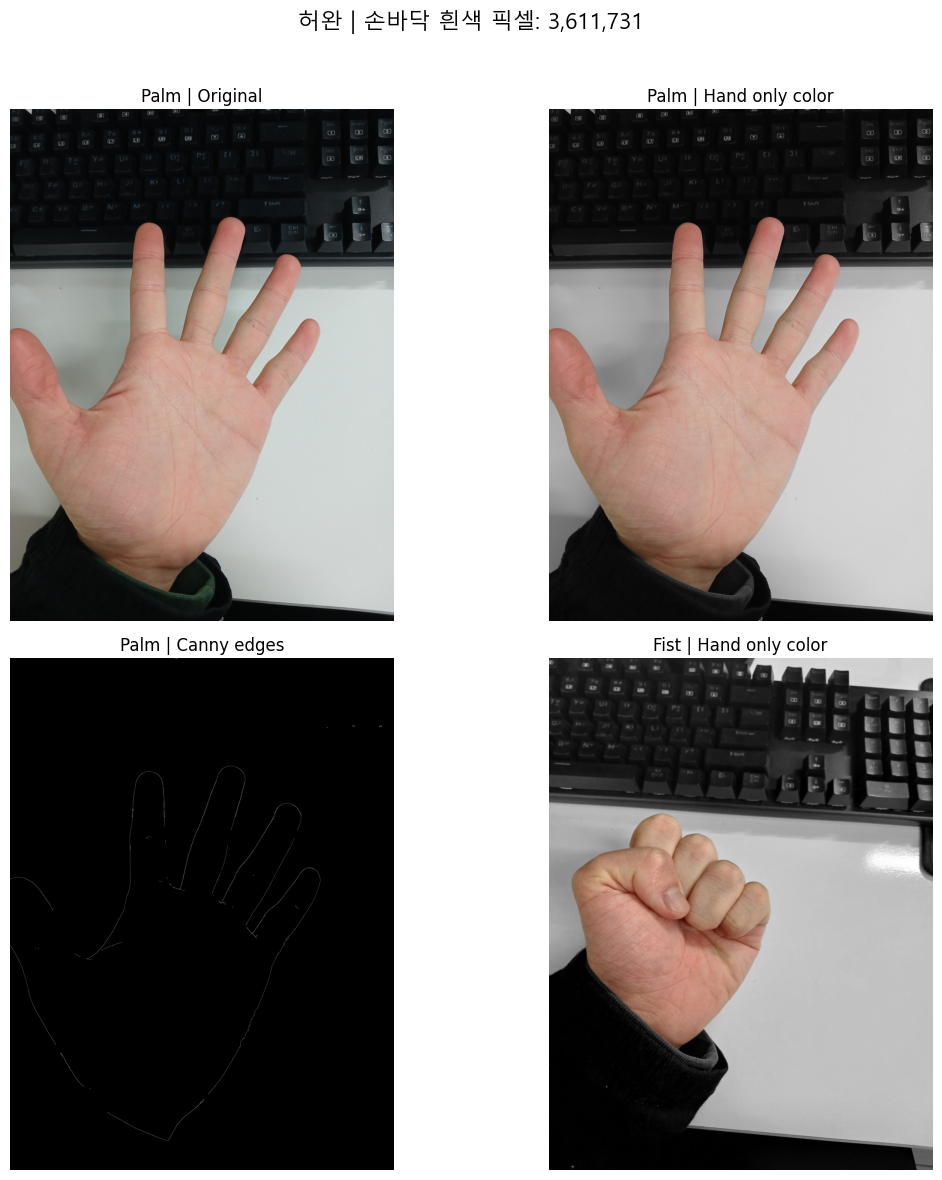

In [57]:
poster_white_pixel_count = np.count_nonzero(palm_mask_clean == 255)
print(f'손바닥 마스크의 흰색 픽셀 수: {poster_white_pixel_count:,}')

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
poster_images = [
    (palm_image, 'Palm | Original'),
    (palm_comparison_color, 'Palm | Hand only color'),
    (blur_edges_high, 'Palm | Canny edges'),
    (fist_color, 'Fist | Hand only color'),
]
for ax, (image, title) in zip(axes.flat, poster_images):
    if image.ndim == 3:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

fig.suptitle(
    f'허완 | 손바닥 흰색 픽셀: {poster_white_pixel_count:,}',
    fontsize=16, fontfamily='Malgun Gothic'
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


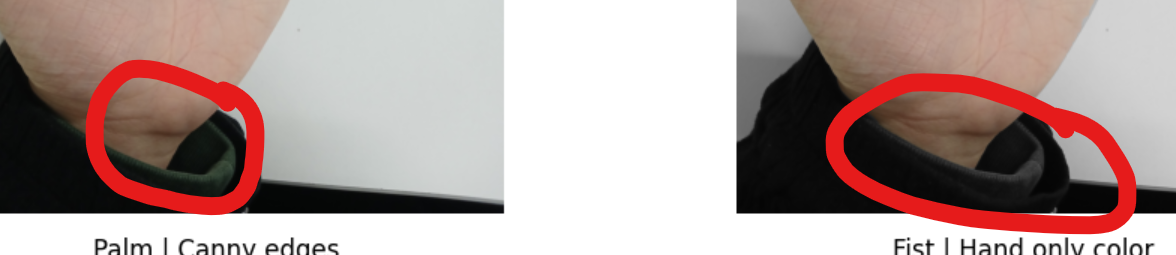